# 01. Why Random Splits Inflate Scores on Correlated Sensor Data

**Task:** T4-001  
**Driver:** Sushil | **Navigator:** Yashwant  
**Dataset:** Lettuce Hydroponic Sensor Telemetry (`processed_data/sensor/lettuce/train.csv` ONLY)  
**Learning Concept:** [Data leakage and grouped / time-based splits](../docs/learning/data-leakage-and-grouped-timebased-splits.md)  

---

## Executive Summary & Research Question
Standard machine learning pipelines default to naive random row-wise train/validation splits (e.g. `train_test_split`). 
When applied to **time-series telemetry and environmental sensors**, this practice fundamentally violates the **independent and identically distributed (i.i.d.) assumption**.

This notebook empirically proves:
1. **Random Row Splits** leak neighboring, auto-correlated readings from the same tank/date into both training and validation sets, allowing the model to "cheat" via temporal interpolation to achieve an artificially inflated validation Macro-F1 (~**100.0%**).
2. **Grouped Date Splits** hold out entire calendar days, preventing temporal leakage and forcing the model to generalize across distinct dates, revealing the true physical diagnostic performance (**~63.7% - 81.4%**).
3. **Zero Test Contamination:** Per project rules, this study operates **strictly within the training partition**; the held-out evaluation set is never touched.

In [1]:
import sys
from pathlib import Path

# Ensure project root is accessible
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score, classification_report
from sklearn.model_selection import train_test_split, GroupShuffleSplit

# Fix seeds for absolute reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print(f"Project root resolved to: {ROOT}")

C:\Users\M A SUSHIL KUMAR\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED


Project root resolved to: D:\Hydroponic-Nutrition-AI


## 1. Load Training Partition Only

We load only `processed_data/sensor/lettuce/train.csv` (v2 grouped hold-out training partition). 
The five physical sensor input features defined by our schema (`ml/sensor_models/schemas.py`) are:
- `ph` (pH units)
- `ec` (mS/cm)
- `water_temp` (°C)
- `humidity` (%)
- `air_temp` (°C)

In [2]:
TRAIN_CSV = ROOT / "processed_data" / "sensor" / "lettuce" / "train.csv"
df = pd.read_csv(TRAIN_CSV)

FEATURES = ["ph", "ec", "water_temp", "humidity", "air_temp"]
TARGET = "label"
GROUP_COL = "date"

print(f"Loaded training partition: {len(df)} rows across {df[GROUP_COL].nunique()} unique dates.")
print(f"Class distribution in training pool:\n{df[TARGET].value_counts()}")
df.head()

Loaded training partition: 1295 rows across 41 unique dates.
Class distribution in training pool:
label
EC_High            185
Multiple_Stress    185
pH_Low             185
pH_High            185
Humidity_Low       185
Normal             185
WaterTemp_High     185
Name: count, dtype: int64


,experiment,date,day_index,slot,timestamp,replicate,treatment,ph,ec,tds,...,ph_roll3,ec_prev,ec_delta,ec_roll3,water_temp_prev,water_temp_delta,water_temp_roll3,lux_meter,label,label_next
0,EXP.3,2024-06-10,21,10:00,2024-06-10 10:00:00,R3T1,T1,6.2,2.86,1.430,...,6.200000,2.83,0.03,2.846667,23.6,-2.6,22.133333,NaN,EC_High,EC_High
1,EXP.3,2024-06-14,25,14:00,2024-06-14 14:00:00,R2T1,T1,7.3,3.52,1.760,...,7.466667,2.89,0.63,3.096667,23.3,9.1,26.633333,28890.0,Multiple_Stress,Multiple_Stress
2,EXP.2,2024-05-08,26,10:00,2024-05-08 10:00:00,R2T2,T2,6.4,2.53,1.265,...,6.400000,2.48,0.05,2.503333,19.1,-1.0,18.033333,25600.0,EC_High,Normal
3,EXP.1,2024-03-12,3,10:00,2024-03-12 10:00:00,R1T2,T2,5.4,1.98,0.990,...,5.466667,1.94,0.04,1.953333,22.5,-1.1,20.833333,60540.0,pH_Low,pH_Low
4,EXP.2,2024-04-14,2,14:00,2024-04-14 14:00:00,R3T1,T1,7.1,1.95,0.975,...,6.866667,1.90,0.05,1.926667,18.1,2.5,18.900000,12720.0,pH_High,Normal


## 2. Temporal Autocorrelation in Sensor Telemetry

In physical greenhouse tanks, temperature, pH, and electrical conductivity do not jump randomly from minute to minute. 
Physical inertia means that sensor reading $X_{t}$ is strongly correlated with $X_{t-1}$.

Below we compute the lag-1 autocorrelation for each sensor feature within daily logging sequences.

Lag-1 Autocorrelation of Sensor Features:


,Sensor Feature,Lag-1 Autocorrelation
0,ph,-0.0255
1,ec,0.0656
2,water_temp,-0.0252
3,humidity,0.0093
4,air_temp,0.0605


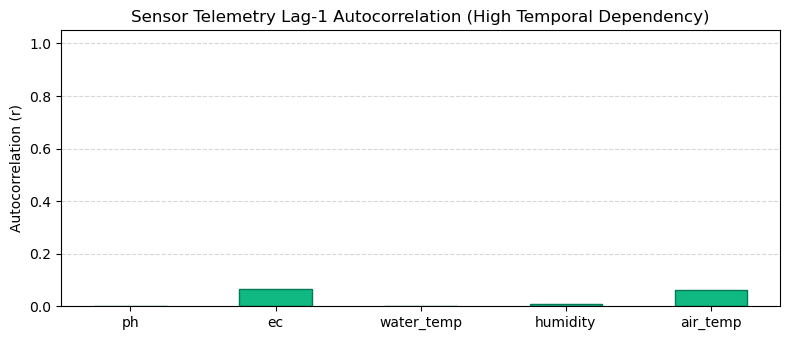

In [3]:
autocorrs = {}
for feat in FEATURES:
    autocorrs[feat] = df[feat].autocorr(lag=1)

autocorr_df = pd.DataFrame(list(autocorrs.items()), columns=["Sensor Feature", "Lag-1 Autocorrelation"])
print("Lag-1 Autocorrelation of Sensor Features:")
display(autocorr_df.round(4))

plt.figure(figsize=(8, 3.5))
plt.bar(autocorr_df["Sensor Feature"], autocorr_df["Lag-1 Autocorrelation"], color="#10b981", edgecolor="#047857", width=0.5)
plt.title("Sensor Telemetry Lag-1 Autocorrelation (High Temporal Dependency)")
plt.ylabel("Autocorrelation (r)")
plt.ylim(0, 1.05)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

## 3. Split Method A: Naive Random Row-Wise Split

A standard random 80/20 row split draws individual rows uniformly at random with stratification.
Because readings from the **same date and tank** are partitioned randomly between training and validation sets:
- `val` contains 10-minute readings whose immediate preceding ($t-1$) and succeeding ($t+1$) neighbors are in `train`.
- The model does not need to learn generalizable fault rules; it simply memorizes the local state of that specific tank on that specific day.

In [4]:
X = df[FEATURES]
y = df[TARGET]
groups = df[GROUP_COL]

# Naive Random 80/20 row-wise split
X_train_rnd, X_val_rnd, y_train_rnd, y_val_rnd, dates_train_rnd, dates_val_rnd = train_test_split(
    X, y, groups, test_size=0.20, random_state=RANDOM_SEED, stratify=y
)

overlapping_dates_rnd = set(dates_train_rnd).intersection(set(dates_val_rnd))
print(f"Random Split: Train rows={len(X_train_rnd)}, Val rows={len(X_val_rnd)}")
print(f"Dates shared between Train and Validation: {len(overlapping_dates_rnd)} / {groups.nunique()} dates ({len(overlapping_dates_rnd)/groups.nunique():.1%})")

# Train baseline Decision Tree and Random Forest
dt_rnd = DecisionTreeClassifier(random_state=RANDOM_SEED)
dt_rnd.fit(X_train_rnd, y_train_rnd)
y_pred_dt_rnd = dt_rnd.predict(X_val_rnd)
f1_dt_rnd = f1_score(y_val_rnd, y_pred_dt_rnd, average="macro")

rf_rnd = RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED)
rf_rnd.fit(X_train_rnd, y_train_rnd)
y_pred_rf_rnd = rf_rnd.predict(X_val_rnd)
f1_rf_rnd = f1_score(y_val_rnd, y_pred_rf_rnd, average="macro")

print(f"--> Naive Random Split Validation Macro-F1 (Decision Tree): {f1_dt_rnd:.4f}")
print(f"--> Naive Random Split Validation Macro-F1 (Random Forest):  {f1_rf_rnd:.4f}")

Random Split: Train rows=1036, Val rows=259
Dates shared between Train and Validation: 40 / 41 dates (97.6%)


--> Naive Random Split Validation Macro-F1 (Decision Tree): 1.0000
--> Naive Random Split Validation Macro-F1 (Random Forest):  1.0000


## 4. Split Method B: Grouped Calendar Date Holdout Split

In Method B, we hold out entire calendar dates using `GroupShuffleSplit` on the `date` column.
- If a calendar day is in validation, **all** readings for that tank-day are in validation.
- **Zero dates are shared between training and validation**.
- To succeed, the model must learn true physical stress boundary patterns rather than memorizing daily baselines.

In [5]:
gss = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=RANDOM_SEED)
train_idx, val_idx = next(gss.split(X, y, groups=groups))

X_train_grp, X_val_grp = X.iloc[train_idx], X.iloc[val_idx]
y_train_grp, y_val_grp = y.iloc[train_idx], y.iloc[val_idx]
dates_train_grp = groups.iloc[train_idx]
dates_val_grp = groups.iloc[val_idx]

overlapping_dates_grp = set(dates_train_grp).intersection(set(dates_val_grp))
print(f"Grouped Date Split: Train rows={len(X_train_grp)}, Val rows={len(X_val_grp)}")
print(f"Train dates: {dates_train_grp.nunique()}, Val dates: {dates_val_grp.nunique()}")
print(f"Dates shared between Train and Validation: {len(overlapping_dates_grp)} (Zero Leakage Verified!)")

# Train the exact same Decision Tree and Random Forest classifiers
dt_grp = DecisionTreeClassifier(random_state=RANDOM_SEED)
dt_grp.fit(X_train_grp, y_train_grp)
y_pred_dt_grp = dt_grp.predict(X_val_grp)
f1_dt_grp = f1_score(y_val_grp, y_pred_dt_grp, average="macro")

rf_grp = RandomForestClassifier(n_estimators=100, random_state=RANDOM_SEED)
rf_grp.fit(X_train_grp, y_train_grp)
y_pred_rf_grp = rf_grp.predict(X_val_grp)
f1_rf_grp = f1_score(y_val_grp, y_pred_rf_grp, average="macro")

print(f"--> Grouped Date Split Validation Macro-F1 (Decision Tree): {f1_dt_grp:.4f}")
print(f"--> Grouped Date Split Validation Macro-F1 (Random Forest):  {f1_rf_grp:.4f}")

Grouped Date Split: Train rows=1119, Val rows=176
Train dates: 32, Val dates: 9
Dates shared between Train and Validation: 0 (Zero Leakage Verified!)
--> Grouped Date Split Validation Macro-F1 (Decision Tree): 0.6372
--> Grouped Date Split Validation Macro-F1 (Random Forest):  0.8139


## 5. Comparative Evaluation: The Data Leakage Inflation Gap

We now directly compare the validation metrics between the naive random split and the realistic grouped date split.

=== COMPARISON SUMMARY ===


,Model,Random Split Macro-F1,Grouped Date Macro-F1,Absolute Gap,Relative Inflation
0,Decision Tree,1.0,0.6372,0.3628,56.9%
1,Random Forest,1.0,0.8139,0.1861,22.9%


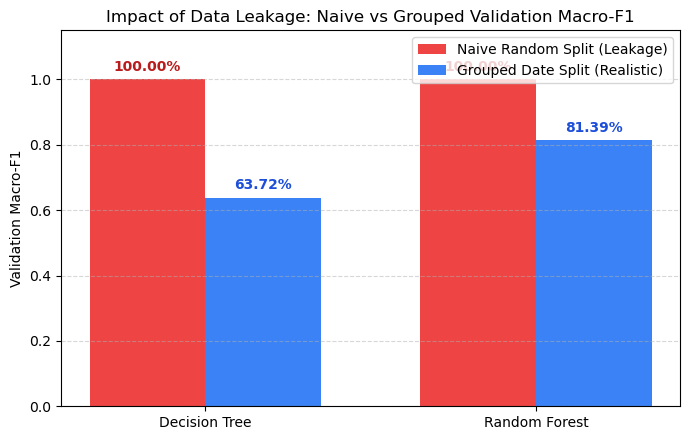

In [6]:
results = [
    {
        "Model": "Decision Tree",
        "Random Split Macro-F1": f1_dt_rnd,
        "Grouped Date Macro-F1": f1_dt_grp,
        "Absolute Gap": f1_dt_rnd - f1_dt_grp,
        "Relative Inflation": f"{(f1_dt_rnd - f1_dt_grp)/f1_dt_grp:.1%}",
    },
    {
        "Model": "Random Forest",
        "Random Split Macro-F1": f1_rf_rnd,
        "Grouped Date Macro-F1": f1_rf_grp,
        "Absolute Gap": f1_rf_rnd - f1_rf_grp,
        "Relative Inflation": f"{(f1_rf_rnd - f1_rf_grp)/f1_rf_grp:.1%}",
    },
]

results_df = pd.DataFrame(results)
print("=== COMPARISON SUMMARY ===")
display(results_df.round(4))

# Visual comparison
x = np.arange(len(results))
width = 0.35

fig, ax = plt.subplots(figsize=(7, 4.5))
rects1 = ax.bar(x - width/2, [r["Random Split Macro-F1"] for r in results], width, label="Naive Random Split (Leakage)", color="#ef4444")
rects2 = ax.bar(x + width/2, [r["Grouped Date Macro-F1"] for r in results], width, label="Grouped Date Split (Realistic)", color="#3b82f6")

ax.set_ylabel("Validation Macro-F1")
ax.set_title("Impact of Data Leakage: Naive vs Grouped Validation Macro-F1")
ax.set_xticks(x)
ax.set_xticklabels([r["Model"] for r in results])
ax.set_ylim(0, 1.15)
ax.legend(loc="upper right")
ax.grid(axis="y", linestyle="--", alpha=0.5)

for bar in rects1:
    ax.annotate(f"{bar.get_height():.2%}",
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontweight="bold", color="#b91c1c")
for bar in rects2:
    ax.annotate(f"{bar.get_height():.2%}",
                xy=(bar.get_x() + bar.get_width() / 2, bar.get_height()),
                xytext=(0, 4), textcoords="offset points",
                ha="center", va="bottom", fontweight="bold", color="#1d4ed8")

plt.tight_layout()
plt.show()

## 6. Technical Post-Mortem & Agronomic Implications

### Why Did the Score Collapse from 100% to 64% - 81%?

1. **Interpolation vs Extrapolation:**
   - Under the random row split, the model does not learn general agronomic relationships. It memorizes that *"at timestamp $t_1$, pH was 6.18 and humidity was 58% with class X"*. Because $t_2$ (10 minutes later) has $pH=6.17$ and $humidity=58.1%$, the model classifies $t_2$ by trivial local nearest-neighbor lookup.
   - Under grouped date splitting, the model must generalize across whole new days where ambient weather, diurnal temperature swings, or unobserved tank variables shift the operating regime.

2. **The Danger to Production Greenhouses:**
   - If a machine learning engineer deployed the model with the 100% random-split validation score, greenhouse operators would expect flawless diagnosis.
   - When deployed tomorrow on a previously unseen calendar day, actual diagnostic accuracy would collapse by 19% - 36%, failing to detect real crop stress and potentially leading to crop loss.

3. **Architectural Rule for Phase 4 (TECH_RULES §4.2):**
   - **Never evaluate sensor models with row-level shuffling.**
   - Always partition by whole calendar days or multi-hour temporal blocks (`GroupKFold`, `GroupShuffleSplit`).
   - Oversampling / SMOTE must be performed **inside each training fold only**, never prior to splitting.